 # Seaborn

In [2]:
# DEF : Seaborn is a high level visulization library.
# seaborn is designed over the matplotlib.

# seaborn is used for complex charts , mainly used for statstical charts , KDE plot , particular.
# seaborn library have in-build datasets.

# install and importing seaborn

In [7]:
# pip install seaborn
import  seaborn as sns

# Build in dataset

In [10]:
print(sns.get_dataset_names())

['anagrams', 'anscombe', 'attention', 'brain_networks', 'car_crashes', 'diamonds', 'dots', 'dowjones', 'exercise', 'flights', 'fmri', 'geyser', 'glue', 'healthexp', 'iris', 'mpg', 'penguins', 'planets', 'seaice', 'taxis', 'tips', 'titanic']


In [17]:
# How to load the dataset from the seaborn

df = sns.load_dataset('flights')
df

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121
...,...,...,...
139,1960,Aug,606
140,1960,Sep,508
141,1960,Oct,461
142,1960,Nov,390


# Line Chart in seaborn

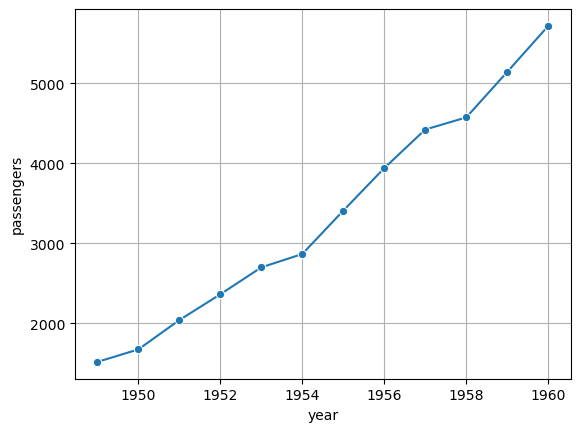

In [29]:
# use : trends over the time
# group the flights dataset year- wise

import matplotlib.pyplot as plt
timeline_year = df.groupby("year")['passengers'].sum().reset_index()
sns.lineplot(x = "year", y = "passengers",data = timeline_year, marker = 'o')
plt.grid()

# You can customeized the seaborn chart using the matplotlib.

# tips dataset

In [32]:
df = sns.load_dataset('tips')
df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


<Axes: xlabel='total_bill', ylabel='tip'>

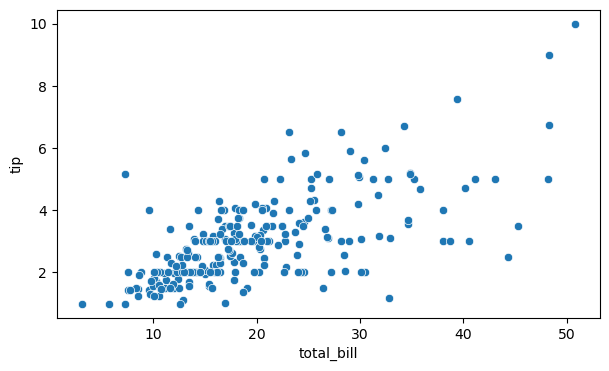

In [38]:
# Query : find the relationship between total bill and tip?

plt.figure(figsize = (7,4))
sns.scatterplot(x = "total_bill" , y = "tip",data = df)

# pairplot 

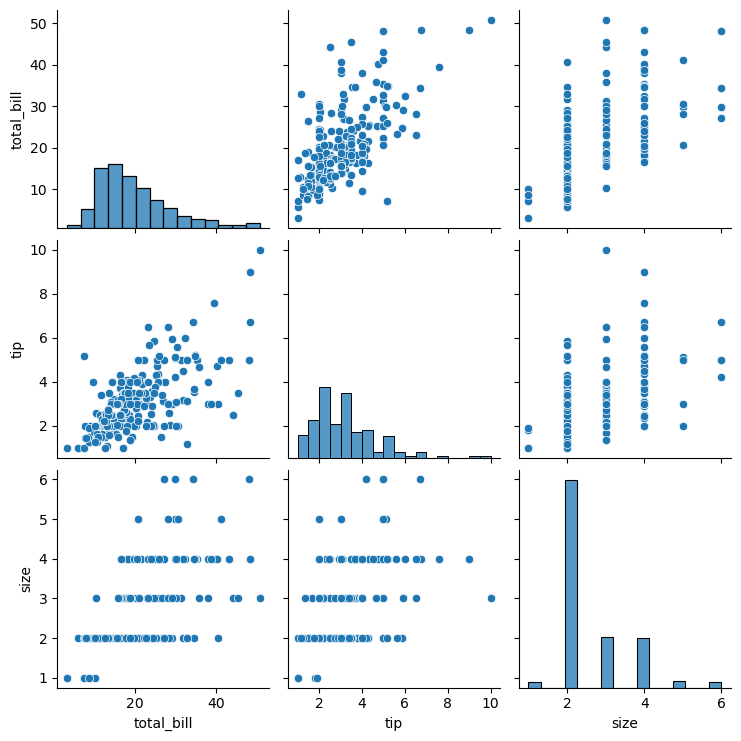

In [44]:
# use : pair shows the relationship between all the numerical varibale together pair- wise.
# Hue : parameter in pairplot, is used for the categorize the data.

sns.pairplot(df)

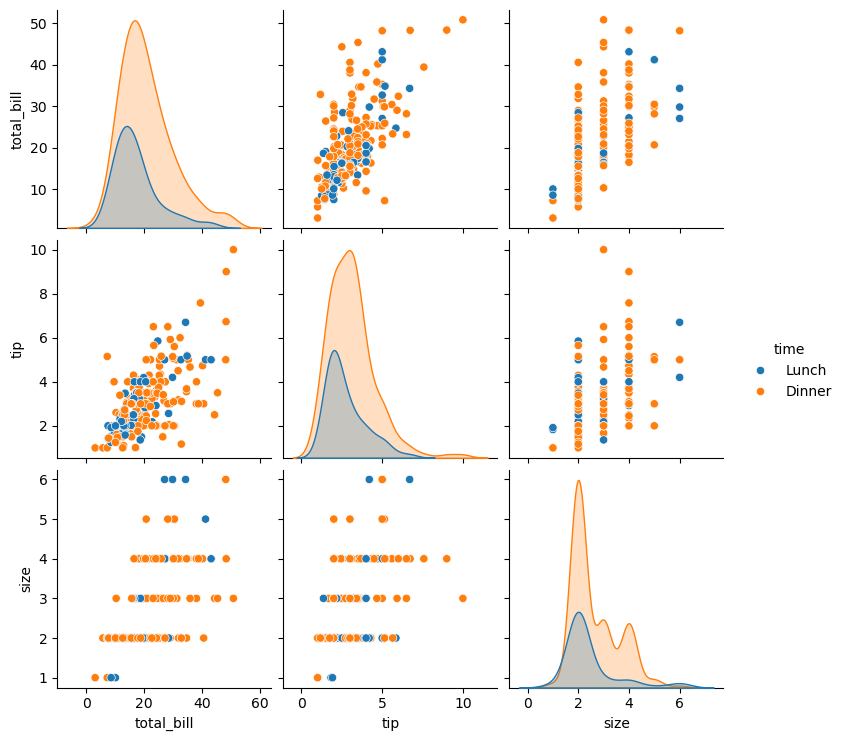

In [52]:
sns.pairplot(df, hue = "time")

# HeatMap 

In [57]:
# HeatMap is used to visualize the correlation between 2 variables in colourful chart.

corr_matrix = df.corr(numeric_only = True)
print(corr_matrix)

            total_bill       tip      size
total_bill    1.000000  0.675734  0.598315
tip           0.675734  1.000000  0.489299
size          0.598315  0.489299  1.000000


<Axes: >

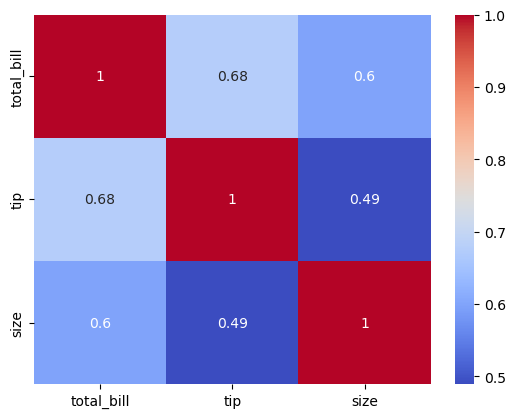

In [61]:
sns.heatmap(corr_matrix, annot = True , cmap = "coolwarm")

# Relationship between Categorical columns

In [72]:
# using pivot table: to find relationship betweeen categorical variables
# Heatmap : make the colorful table for showing pivot table

# categorical columns : sex, day , time, smoker

pivot = df.pivot_table(index = "day", columns = ["sex","smoker"], aggfunc = "size", observed=True, fill_value = 0)
pivot

sex    Male     Female    
smoker  Yes  No    Yes  No
day                       
Thur     10  20      7  25
Fri       8   2      7   2
Sat      27  32     15  13
Sun      15  43      4  14

<Axes: xlabel='sex-smoker', ylabel='day'>

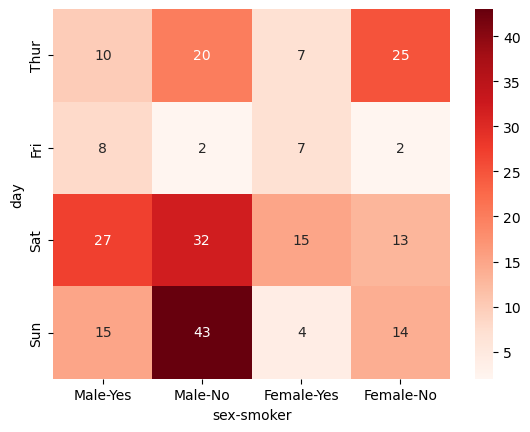

In [74]:
sns.heatmap(pivot, annot = True, cmap = "Reds" )


# countplot : showing frequency of categorical data

<Axes: xlabel='day', ylabel='count'>

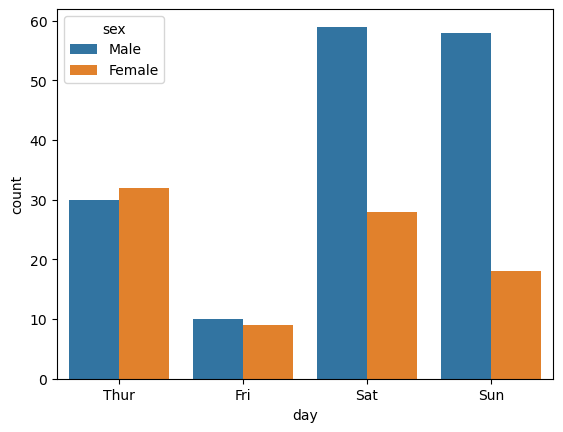

In [81]:
sns.countplot(data = df, x = "day", hue = "sex")

<Axes: ylabel='tip'>

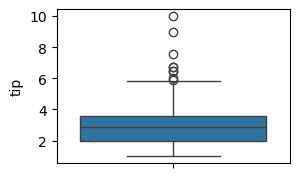

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt
df = sns.load_dataset('tips')
plt.figure(figsize = (3,2))
sns.boxplot(y='tip', data = df)

# use : Box plot is used for finding the outliers.

In [21]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<Axes: xlabel='day', ylabel='total_bill'>

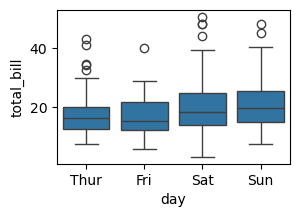

In [25]:
df = sns.load_dataset('tips')
plt.figure(figsize = (3,2))
sns.boxplot(x = "day",y='total_bill', data = df)

<Axes: xlabel='day', ylabel='tip'>

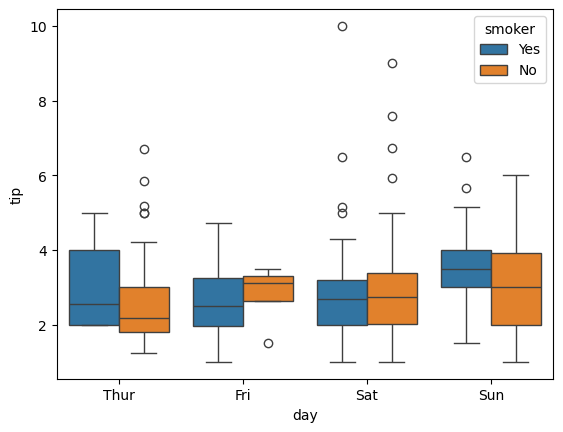

In [29]:
sns.boxplot(x = "day",y='tip', data = df, hue = 'smoker')

# Density Plot (KDE plot)

<Axes: xlabel='total_bill', ylabel='Density'>

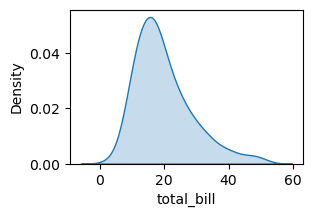

In [32]:
# KDE : kernal denisty Estimate
# Use :  Density plot is used to visulize probability of a cintinuous data.

plt.figure(figsize = (3,2))
sns.kdeplot(data = df, x = "total_bill",fill = True)

# Violin plot

<Axes: xlabel='day', ylabel='total_bill'>

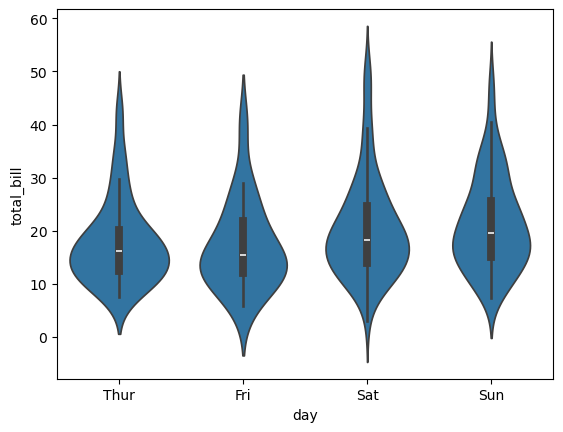

In [35]:
# violin plot = Box plot + Density plot
sns.violinplot(x = 'day', y = 'total_bill', data = df)

# Regression Plot

<Axes: xlabel='total_bill', ylabel='tip'>

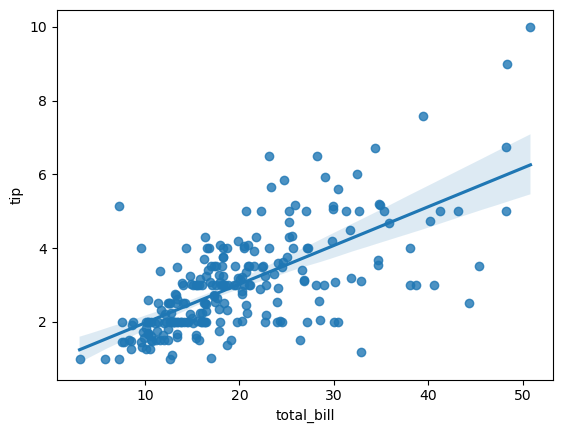

In [40]:
# Use :  To plot the linear regressive line.

sns.regplot(x = "total_bill",y = "tip", data = df)

# FacetGrid

<Figure size 300x200 with 0 Axes>

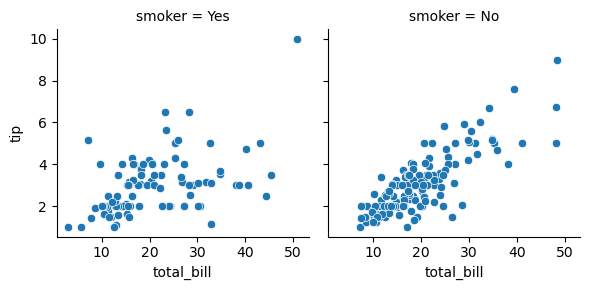

In [46]:
# Use: create multiple plots based on classes in categorical varibable.

plt.figure(figsize = (3,2))
g = sns.FacetGrid(df, col = 'smoker')
g.map_dataframe(sns.scatterplot, x = 'total_bill',y= 'tip')

<Figure size 300x200 with 0 Axes>

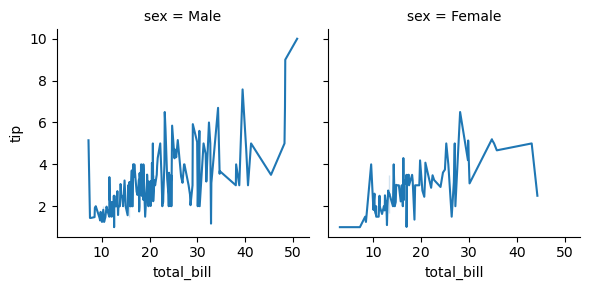

In [50]:
# Use: create multiple plots based on classes in categorical varibable.

plt.figure(figsize = (3,2))
g = sns.FacetGrid(df, col = 'sex')
g.map_dataframe(sns.lineplot, x = 'total_bill',y= 'tip')

# Joint Plot

<Figure size 200x100 with 0 Axes>

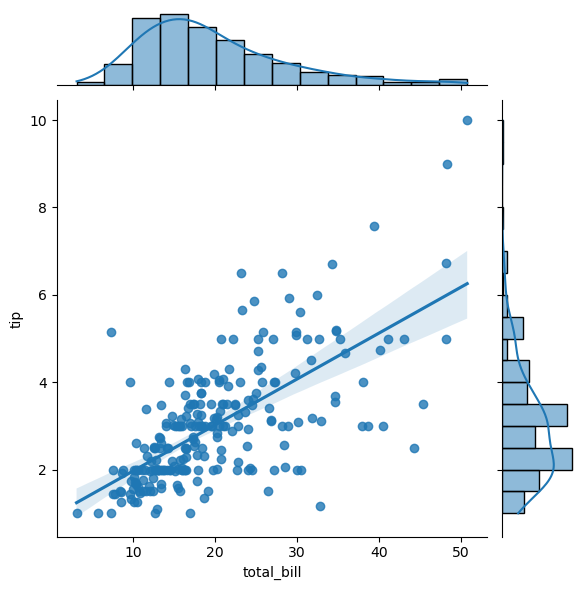

In [57]:
# use : combine 2 plots : Histogram + scatterplot

plt.figure(figsize = (2,1))
sns.jointplot(data = df , x = "total_bill", y = "tip",kind = "reg")

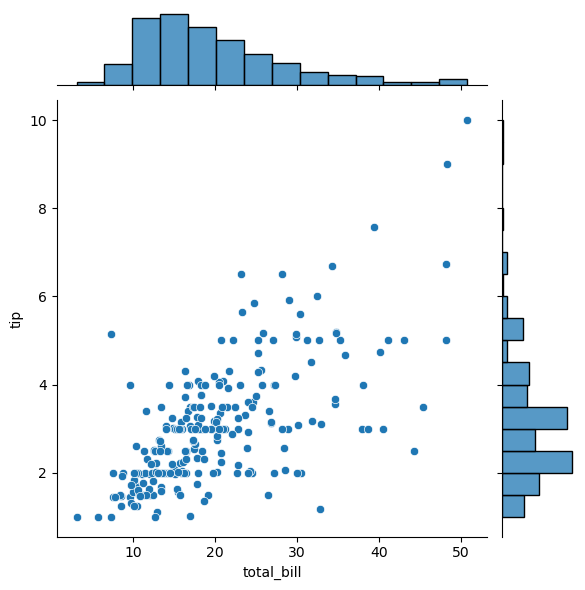

In [59]:
sns.jointplot(data = df , x = "total_bill", y = "tip",kind = "scatter")